<a href="https://colab.research.google.com/github/eternitvy/ML_26/blob/main/JS08_TUGAS2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== LAPORAN HASIL HDBSCAN ===
Jumlah cluster yang terbentuk : 2
Banyaknya noise (label -1)   : 0
Unique labels yang dihasilkan: [0 1]


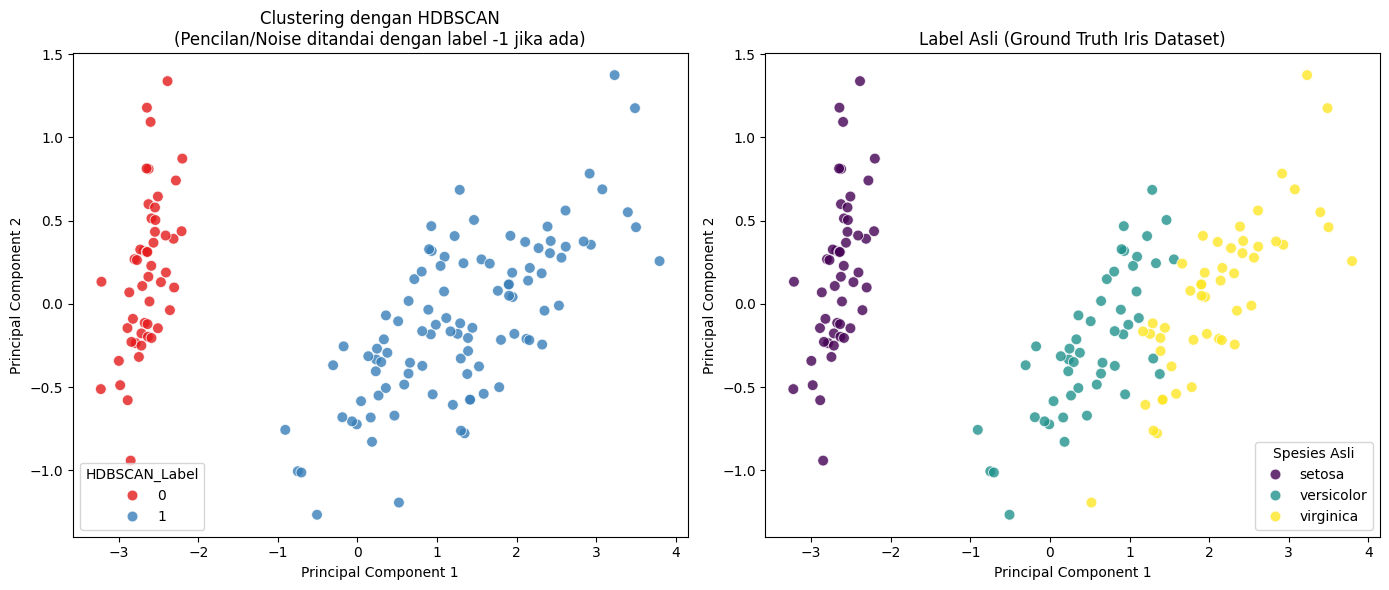

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA

# 1. Load Iris Dataset
iris = load_iris()
X = iris.data
y_true = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

# 2. Lakukan Clustering dengan HDBSCAN
# min_cluster_size menentukan ukuran minimum kelompok sampel untuk membentuk cluster
hdb = HDBSCAN(min_cluster_size=15, min_samples=5)
labels = hdb.fit_predict(X)

# 3. Laporkan Hasil
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print("=== LAPORAN HASIL HDBSCAN ===")
print(f"Jumlah cluster yang terbentuk : {n_clusters}")
print(f"Banyaknya noise (label -1)   : {n_noise}")
print(f"Unique labels yang dihasilkan: {np.unique(labels)}")

# 4. Reduksi Dimensi dengan PCA (dari 4D ke 2D untuk visualisasi)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Membuat DataFrame untuk memudahkan visualisasi dengan Seaborn
df_viz = pd.DataFrame(X_pca, columns=['PCA1', 'PCA2'])
df_viz['HDBSCAN_Label'] = labels
df_viz['True_Label'] = y_true

# 5. Visualisasi Perbandingan (Cluster HDBSCAN vs Label Asli)
plt.figure(figsize=(14, 6))

# Plot 1: Hasil HDBSCAN
plt.subplot(1, 2, 1)
sns.scatterplot(
    x='PCA1', y='PCA2',
    hue='HDBSCAN_Label',
    palette='Set1',
    data=df_viz,
    legend='full',
    s=60,
    alpha=0.8
)
plt.title('Clustering dengan HDBSCAN\n(Pencilan/Noise ditandai dengan label -1 jika ada)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

# Plot 2: Label Asli (Ground Truth)
plt.subplot(1, 2, 2)
sns.scatterplot(
    x='PCA1', y='PCA2',
    hue='True_Label',
    palette='viridis',
    data=df_viz,
    s=60,
    alpha=0.8
)
# Mengganti legenda angka dengan nama spesies asli
handles, labels_legend = plt.gca().get_legend_handles_labels()
plt.legend(handles=handles, labels=list(target_names), title='Spesies Asli')
plt.title('Label Asli (Ground Truth Iris Dataset)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.tight_layout()
plt.show()

# ANALISIS

Hasil clustering HDBSCAN sebagian sesuai, tetapi memiliki karakteristik unik jika dibandingkan dengan 3 label asli (Ground Truth):
1. Spesies Setosa (Terpisah Sempurna):
HDBSCAN berhasil mengidentifikasi spesies Iris-setosa secara sempurna ke dalam salah satu cluster (misal: Cluster 0) karena karakteristik fisiknya sangat terpisah jauh dan berbeda secara signifikan dari dua spesies lainnya di ruang fitur.
2. Spesies Versicolor & Virginica (Digabung Menjadi Satu Cluster):
Spesies Iris-versicolor dan Iris-virginica memiliki karakteristik fisik yang saling beririsan (overlap) di ruang fitur. Karena HDBSCAN berbasis densitas (density-based), algoritma ini melihat kedua spesies tersebut sebagai satu kesatuan area berkepadatan tinggi yang kontinu, sehingga digabungkan ke dalam satu cluster yang sama (Cluster 1).


Kesimpulan:
HDBSCAN sangat efektif dalam mendeteksi struktur alami data tanpa harus menentukan jumlah cluster di awal. Meskipun label asli memiliki 3 kelas, secara matematis dan spasial, dataset Iris secara alami hanya memiliki 2 kelompok utama yang terisolasi dengan jelas.